#### Ejemplo de aplicación de Gradient Descent Algorithm para encontrar los valores óptimos de un modelo de regresión

Recordemos que un modelo de regresión lineal tiene la siguiente forma

$$ \hat{y} = \beta_0 + \beta_1 x $$

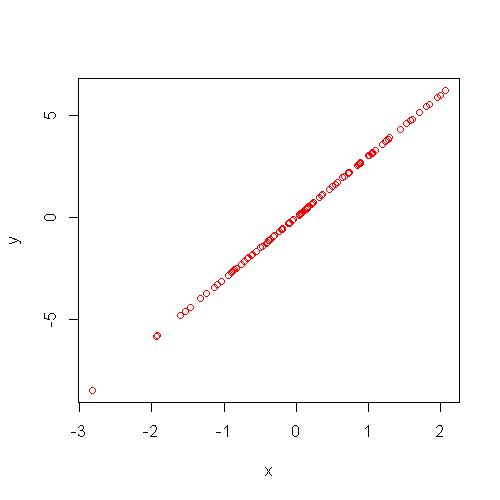

In [1]:
options(repr.plot.width = 5, repr.plot.height = 5, repr.plot.res = 100)

df <- data.frame(x = rnorm(n = 100, mean = 0, sd = 1))
df$y <- 3*df$x + 0 * rnorm(n = 100, mean = 0, sd = 0.5)

plot(df, col = 'red')

Un modelo de regresión lineal utiliza el error cuadratico medio como métrica de pérdida para realizar el ajuste de parámetros

$$ MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 $$

Recordemos que,

$$ \hat{y}_i = \beta_0 + \beta_1 x_i $$

Por simplificación supongamos que $\beta_0 = 0$, por lo que podemos escribir el MSE de la siguiente forma

$$ MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - (\beta_1 x_i))^2 $$

Lo que nos deja la siguiente expresión al realizar 

$$ MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \beta_1 x_i)^2 $$

Aplicando derivada del MSE respecto a $\beta_1$ tenemos lo siguiente,

$$ \frac{\partial(MSE)}{\partial\beta_1} = 2 \frac{1}{n} \sum_{i=1}^{n} (y_i - \beta_1 x_i)(-x_i) = 0 $$

$$ \frac{\partial(MSE)}{\partial\beta_1} = \frac{-2}{n} \sum_{i=1}^{n} (y_ix_i - \beta_1 x_i^2)) = D_{\beta_1} $$

Con lo anterior podemos escribir nuestra función de actualización,

$$ \beta_{1, t+1} = \beta_{1, t} - \alpha \times D_{\beta_1} $$

En lo anterior $\alpha$ representa la tasa de aprendizaje (learning rate)

In [10]:
alpha = 0.01
epocas = 1000
n = nrow(df)

beta_1 = 0

for (i in 1:epocas){
    Y_pred = beta_1 * df$x
    D_b = (-2 / n) * sum(df$y * df$x - beta_1 * df$x**2)
    beta_1 = beta_1 - alpha * D_b
}

print(beta_1)

[1] 3


Si utilizamos un learning rate muy bajo y poca cantidad de epocas el modelo no converge

In [3]:
alpha = 0.0000001
epocas = 10000
n = nrow(df)

beta_1 = 0

for (i in 1:epocas){
    Y_pred = beta_1 * df$x
    D_b = (-2 / n) * sum(df$y * df$x - beta_1 * df$x**2)
    beta_1 = beta_1 - alpha * D_b
}

print(beta_1)

[1] 0.00573068


Si utilizamos un learning rate muy alto y poca cantidad de epocas el modelo no converge

In [4]:
alpha = 0.99
epocas = 20
n = nrow(df)

beta_1 = 0

for (i in 1:epocas){
    Y_pred = beta_1 * df$x
    D_b = (-2 / n) * sum(df$y * df$x - beta_1 * df$x**2)
    beta_1 = beta_1 - alpha * D_b
}

print(beta_1)

[1] 2.688473
